In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
short = pd.read_csv(
    "data/processed/short_with_regime.csv",
    index_col=0,
    parse_dates=True
)

medium = pd.read_csv(
    "data/processed/medium_with_regime.csv",
    index_col=0,
    parse_dates=True
)

long = pd.read_csv(
    "data/processed/long_with_regime.csv",
    index_col=0,
    parse_dates=True
)

In [3]:
short.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.012082,-0.017108,-0.007482,-0.021634,Normal
2015-02-04,-0.006297,0.011303,0.009490,0.012572,Normal
2015-02-05,0.007191,0.000838,0.007487,-0.036156,Normal
2015-02-06,-0.006461,-0.007030,-0.020922,0.029333,Normal
2015-02-09,-0.008716,0.007205,0.009437,-0.009858,Normal


In [4]:
print("Short:", short.shape)
print("Medium:", medium.shape)
print("Long:", long.shape)

Short: (2932, 5)
Medium: (2932, 5)
Long: (2932, 5)


In [5]:
print(short["Regime"].value_counts())

Regime
Normal    2375
Stress     557
Name: count, dtype: int64


In [6]:
def empirical_lower_tail_dependence(x, y, q=0.05):
    
    x = pd.Series(x).dropna()
    y = pd.Series(y).dropna()
    
    common_index = x.index.intersection(y.index)
    
    x = x.loc[common_index]
    y = y.loc[common_index]
    
    qx = x.quantile(q)
    qy = y.quantile(q)
    
    x_extreme = x <= qx
    y_extreme = y <= qy
    
    joint_extreme = x_extreme & y_extreme
    
    if x_extreme.sum() == 0:
        return np.nan
    
    lambda_empirical = (
        joint_extreme.sum()
        /
        x_extreme.sum()
    )
    
    return lambda_empirical

In [7]:
test_lambda = empirical_lower_tail_dependence(
    short["SPY"],
    short["BTC-USD"],
    q=0.05
)

print(test_lambda)

0.1292517006802721


In [8]:
pairs = [
    ("SPY", "TLT"),
    ("SPY", "GLD"),
    ("SPY", "BTC-USD"),
    ("TLT", "GLD"),
    ("TLT", "BTC-USD"),
    ("GLD", "BTC-USD")
]

In [9]:
short_normal = short[
    short["Regime"] == "Normal"
].drop(columns="Regime")

short_stress = short[
    short["Regime"] == "Stress"
].drop(columns="Regime")

In [10]:
medium_normal = medium[
    medium["Regime"] == "Normal"
].drop(columns="Regime")

medium_stress = medium[
    medium["Regime"] == "Stress"
].drop(columns="Regime")

In [11]:
long_normal = long[
    long["Regime"] == "Normal"
].drop(columns="Regime")

long_stress = long[
    long["Regime"] == "Stress"
].drop(columns="Regime")

In [12]:
datasets = {
    "Short_Normal": short_normal,
    "Short_Stress": short_stress,
    "Medium_Normal": medium_normal,
    "Medium_Stress": medium_stress,
    "Long_Normal": long_normal,
    "Long_Stress": long_stress
}

In [13]:
tail_results = []

for asset1, asset2 in pairs:
    
    row = {
        "Pair": f"{asset1}-{asset2}"
    }
    
    for dataset_name, dataset in datasets.items():
        
        row[dataset_name] = empirical_lower_tail_dependence(
            dataset[asset1],
            dataset[asset2],
            q=0.05
        )
    
    tail_results.append(row)

empirical_tail_table = pd.DataFrame(
    tail_results
)

empirical_tail_table

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,0.109244,0.071429,0.058824,0.071429,0.142857,0.000000
1,SPY-GLD,0.100840,0.107143,0.092437,0.321429,0.092437,0.428571
2,SPY-BTC-USD,0.109244,0.214286,0.109244,0.214286,0.117647,0.535714
3,TLT-GLD,0.092437,0.107143,0.117647,0.178571,0.260504,0.071429
4,TLT-BTC-USD,0.050420,0.071429,0.025210,0.214286,0.000000,0.000000
5,GLD-BTC-USD,0.067227,0.142857,0.126050,0.107143,0.050420,0.428571


In [14]:
display_table = empirical_tail_table.copy()

numeric_cols = display_table.columns[1:]

display_table[numeric_cols] = (
    display_table[numeric_cols]
    .round(3)
)

display_table

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,0.109,0.071,0.059,0.071,0.143,0.000
1,SPY-GLD,0.101,0.107,0.092,0.321,0.092,0.429
2,SPY-BTC-USD,0.109,0.214,0.109,0.214,0.118,0.536
3,TLT-GLD,0.092,0.107,0.118,0.179,0.261,0.071
4,TLT-BTC-USD,0.050,0.071,0.025,0.214,0.000,0.000
5,GLD-BTC-USD,0.067,0.143,0.126,0.107,0.050,0.429


In [15]:
stress_change = pd.DataFrame({
    "Pair": empirical_tail_table["Pair"],
    
    "Short_Change": (
        empirical_tail_table["Short_Stress"]
        -
        empirical_tail_table["Short_Normal"]
    ),
    
    "Medium_Change": (
        empirical_tail_table["Medium_Stress"]
        -
        empirical_tail_table["Medium_Normal"]
    ),
    
    "Long_Change": (
        empirical_tail_table["Long_Stress"]
        -
        empirical_tail_table["Long_Normal"]
    )
})

stress_change

,Pair,Short_Change,Medium_Change,Long_Change
0,SPY-TLT,-0.037815,0.012605,-0.142857
1,SPY-GLD,0.006303,0.228992,0.336134
2,SPY-BTC-USD,0.105042,0.105042,0.418067
3,TLT-GLD,0.014706,0.060924,-0.189076
4,TLT-BTC-USD,0.021008,0.189076,0.000000
5,GLD-BTC-USD,0.075630,-0.018908,0.378151


In [16]:
epsilon = 1e-6

dfr_table = pd.DataFrame({
    "Pair": empirical_tail_table["Pair"],
    
    "Short_DFR": (
        empirical_tail_table["Short_Stress"]
        /
        (
            empirical_tail_table["Short_Normal"]
            + epsilon
        )
    ),
    
    "Medium_DFR": (
        empirical_tail_table["Medium_Stress"]
        /
        (
            empirical_tail_table["Medium_Normal"]
            + epsilon
        )
    ),
    
    "Long_DFR": (
        empirical_tail_table["Long_Stress"]
        /
        (
            empirical_tail_table["Long_Normal"]
            + epsilon
        )
    )
})

dfr_table

,Pair,Short_DFR,Medium_DFR,Long_DFR
0,SPY-TLT,0.653840,1.214265,0.000000
1,SPY-GLD,1.062489,3.477235,4.636313
2,SPY-BTC-USD,1.961521,1.961521,4.553533
3,TLT-GLD,1.159078,1.517844,0.274192
4,TLT-BTC-USD,1.416639,8.499663,0.000000
5,GLD-BTC-USD,2.124968,0.849993,8.499831


In [17]:
spy_btc = empirical_tail_table[
    empirical_tail_table["Pair"] == "SPY-BTC-USD"
].iloc[0]

In [18]:
spy_btc_plot = pd.DataFrame({
    "Normal": [
        spy_btc["Short_Normal"],
        spy_btc["Medium_Normal"],
        spy_btc["Long_Normal"]
    ],
    
    "Stress": [
        spy_btc["Short_Stress"],
        spy_btc["Medium_Stress"],
        spy_btc["Long_Stress"]
    ]
},
index=[
    "Short",
    "Medium",
    "Long"
])

spy_btc_plot

,Normal,Stress
Short,0.109244,0.214286
Medium,0.109244,0.214286
Long,0.117647,0.535714


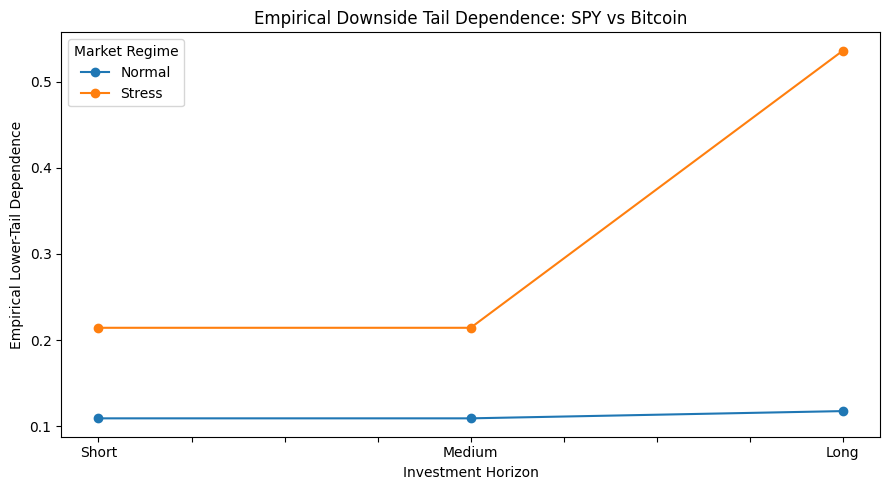

In [19]:
spy_btc_plot.plot(
    figsize=(9, 5),
    marker="o"
)

plt.title(
    "Empirical Downside Tail Dependence: SPY vs Bitcoin"
)

plt.xlabel(
    "Investment Horizon"
)

plt.ylabel(
    "Empirical Lower-Tail Dependence"
)

plt.legend(
    title="Market Regime"
)

plt.tight_layout()
plt.show()

In [20]:
spy_tlt = empirical_tail_table[
    empirical_tail_table["Pair"] == "SPY-TLT"
].iloc[0]

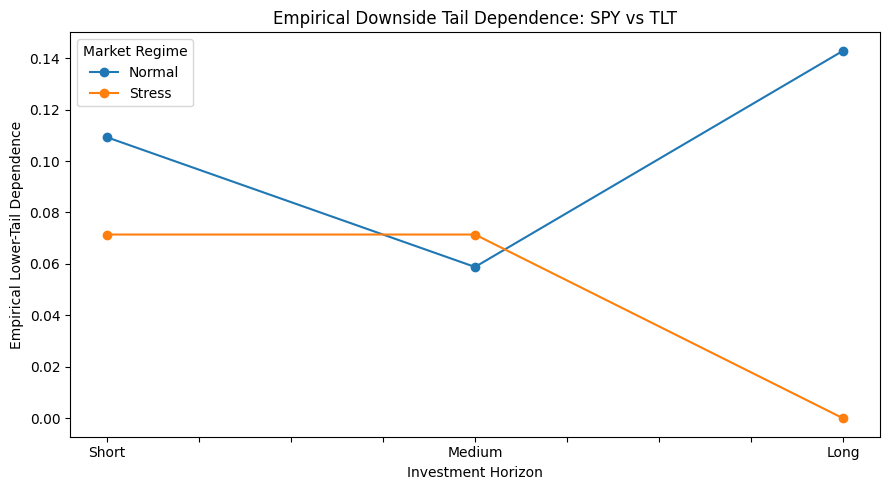

In [21]:
spy_tlt_plot = pd.DataFrame({
    "Normal": [
        spy_tlt["Short_Normal"],
        spy_tlt["Medium_Normal"],
        spy_tlt["Long_Normal"]
    ],
    
    "Stress": [
        spy_tlt["Short_Stress"],
        spy_tlt["Medium_Stress"],
        spy_tlt["Long_Stress"]
    ]
},
index=[
    "Short",
    "Medium",
    "Long"
])

spy_tlt_plot.plot(
    figsize=(9, 5),
    marker="o"
)

plt.title(
    "Empirical Downside Tail Dependence: SPY vs TLT"
)

plt.xlabel("Investment Horizon")
plt.ylabel("Empirical Lower-Tail Dependence")
plt.legend(title="Market Regime")

plt.tight_layout()
plt.show()

In [22]:
spy_gld = empirical_tail_table[
    empirical_tail_table["Pair"] == "SPY-GLD"
].iloc[0]

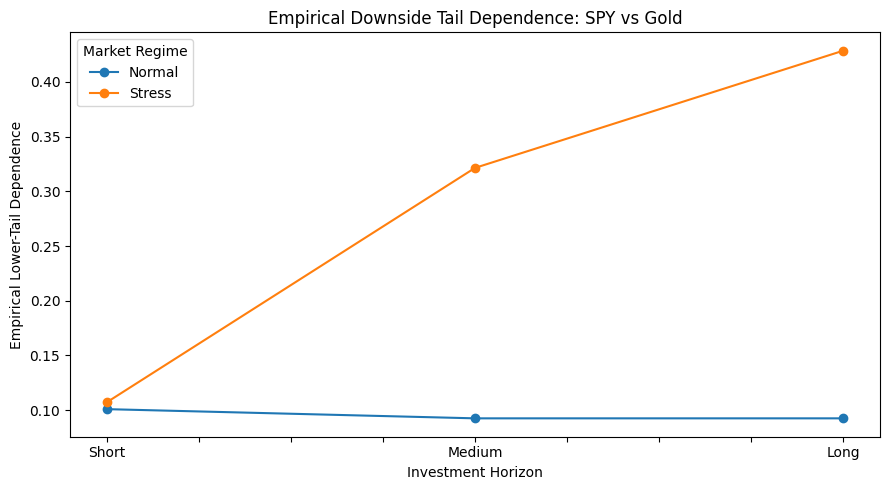

In [23]:
spy_gld_plot = pd.DataFrame({
    "Normal": [
        spy_gld["Short_Normal"],
        spy_gld["Medium_Normal"],
        spy_gld["Long_Normal"]
    ],
    
    "Stress": [
        spy_gld["Short_Stress"],
        spy_gld["Medium_Stress"],
        spy_gld["Long_Stress"]
    ]
},
index=[
    "Short",
    "Medium",
    "Long"
])

spy_gld_plot.plot(
    figsize=(9, 5),
    marker="o"
)

plt.title(
    "Empirical Downside Tail Dependence: SPY vs Gold"
)

plt.xlabel("Investment Horizon")
plt.ylabel("Empirical Lower-Tail Dependence")
plt.legend(title="Market Regime")

plt.tight_layout()
plt.show()

In [24]:
heatmap_data = empirical_tail_table.set_index(
    "Pair"
)

heatmap_data

,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
SPY-TLT,0.109244,0.071429,0.058824,0.071429,0.142857,0.000000
SPY-GLD,0.100840,0.107143,0.092437,0.321429,0.092437,0.428571
SPY-BTC-USD,0.109244,0.214286,0.109244,0.214286,0.117647,0.535714
TLT-GLD,0.092437,0.107143,0.117647,0.178571,0.260504,0.071429
TLT-BTC-USD,0.050420,0.071429,0.025210,0.214286,0.000000,0.000000
GLD-BTC-USD,0.067227,0.142857,0.126050,0.107143,0.050420,0.428571


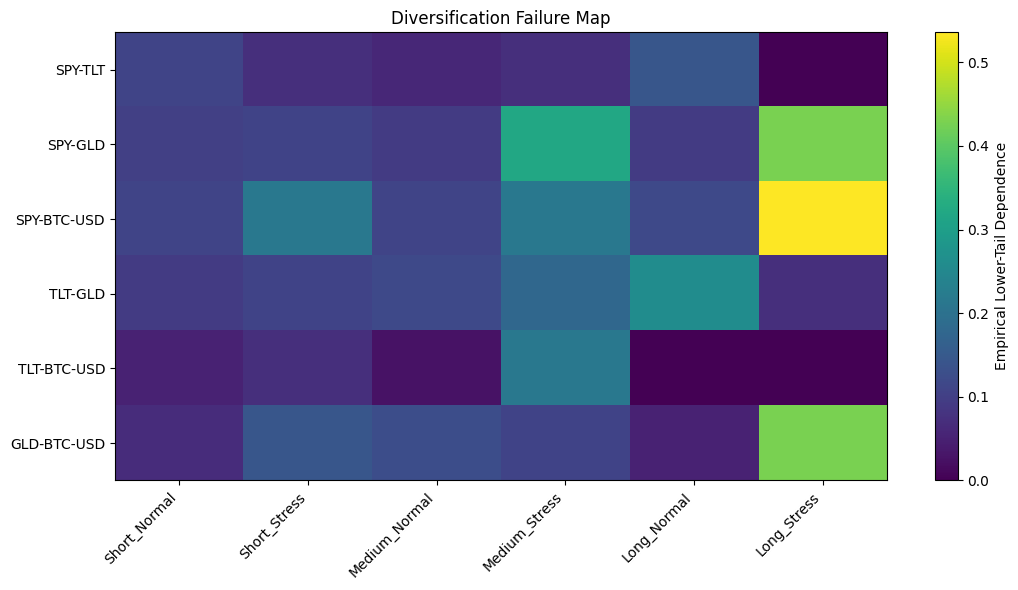

In [25]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

im = ax.imshow(
    heatmap_data.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(heatmap_data.columns))
)

ax.set_xticklabels(
    heatmap_data.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(heatmap_data.index))
)

ax.set_yticklabels(
    heatmap_data.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Empirical Lower-Tail Dependence"
)

ax.set_title(
    "Diversification Failure Map"
)

plt.tight_layout()
plt.show()

In [26]:
def extreme_count(series, q=0.05):
    
    threshold = series.quantile(q)
    
    return (
        series <= threshold
    ).sum()

In [27]:
tail_counts = []

for dataset_name, dataset in datasets.items():
    
    for asset in dataset.columns:
        
        tail_counts.append({
            "Dataset": dataset_name,
            "Asset": asset,
            "Observations": len(dataset),
            "Tail_Observations": extreme_count(
                dataset[asset],
                q=0.05
            )
        })

tail_counts = pd.DataFrame(
    tail_counts
)

tail_counts

,Dataset,Asset,Observations,Tail_Observations
0,Short_Normal,SPY,2375,119
1,Short_Normal,TLT,2375,119
2,Short_Normal,GLD,2375,119
3,Short_Normal,BTC-USD,2375,119
4,Short_Stress,SPY,557,28
5,Short_Stress,TLT,557,28
6,Short_Stress,GLD,557,28
7,Short_Stress,BTC-USD,557,28
8,Medium_Normal,SPY,2375,119
9,Medium_Normal,TLT,2375,119


In [28]:
tail_results_10 = []

for asset1, asset2 in pairs:
    
    row = {
        "Pair": f"{asset1}-{asset2}"
    }
    
    for dataset_name, dataset in datasets.items():
        
        row[dataset_name] = empirical_lower_tail_dependence(
            dataset[asset1],
            dataset[asset2],
            q=0.10
        )
    
    tail_results_10.append(row)

empirical_tail_table_10 = pd.DataFrame(
    tail_results_10
)

empirical_tail_table_10

,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,0.159664,0.125000,0.126050,0.142857,0.226891,0.000000
1,SPY-GLD,0.163866,0.196429,0.159664,0.303571,0.172269,0.267857
2,SPY-BTC-USD,0.180672,0.285714,0.126050,0.267857,0.235294,0.303571
3,TLT-GLD,0.201681,0.250000,0.184874,0.285714,0.239496,0.232143
4,TLT-BTC-USD,0.096639,0.125000,0.071429,0.125000,0.042017,0.000000
5,GLD-BTC-USD,0.113445,0.125000,0.180672,0.160714,0.151261,0.285714


In [29]:
comparison_5_10 = pd.DataFrame({
    "5% Tail": empirical_tail_table[
        empirical_tail_table["Pair"] == "SPY-BTC-USD"
    ].iloc[0, 1:].values,
    
    "10% Tail": empirical_tail_table_10[
        empirical_tail_table_10["Pair"] == "SPY-BTC-USD"
    ].iloc[0, 1:].values
},
index=empirical_tail_table.columns[1:])

comparison_5_10

,5% Tail,10% Tail
Short_Normal,0.109244,0.180672
Short_Stress,0.214286,0.285714
Medium_Normal,0.109244,0.12605
Medium_Stress,0.214286,0.267857
Long_Normal,0.117647,0.235294
Long_Stress,0.535714,0.303571


In [30]:
empirical_tail_table.to_csv(
    "outputs/tables/empirical_tail_dependence_5pct.csv",
    index=False
)

In [31]:
empirical_tail_table_10.to_csv(
    "outputs/tables/empirical_tail_dependence_10pct.csv",
    index=False
)

In [32]:
stress_change.to_csv(
    "outputs/tables/tail_dependence_stress_change.csv",
    index=False
)

In [33]:
dfr_table.to_csv(
    "outputs/tables/diversification_fragility_ratio.csv",
    index=False
)

In [34]:
tail_counts.to_csv(
    "outputs/tables/tail_observation_counts.csv",
    index=False
)

In [35]:
print("Notebook 05 completed successfully.")

print("\n5% empirical tail dependence:")
display(empirical_tail_table.round(3))

print("\nDiversification Fragility Ratio:")
display(dfr_table.round(2))

Notebook 05 completed successfully.

5% empirical tail dependence:


,Pair,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
0,SPY-TLT,0.109,0.071,0.059,0.071,0.143,0.000
1,SPY-GLD,0.101,0.107,0.092,0.321,0.092,0.429
2,SPY-BTC-USD,0.109,0.214,0.109,0.214,0.118,0.536
3,TLT-GLD,0.092,0.107,0.118,0.179,0.261,0.071
4,TLT-BTC-USD,0.050,0.071,0.025,0.214,0.000,0.000
5,GLD-BTC-USD,0.067,0.143,0.126,0.107,0.050,0.429



Diversification Fragility Ratio:


,Pair,Short_DFR,Medium_DFR,Long_DFR
0,SPY-TLT,0.65,1.21,0.00
1,SPY-GLD,1.06,3.48,4.64
2,SPY-BTC-USD,1.96,1.96,4.55
3,TLT-GLD,1.16,1.52,0.27
4,TLT-BTC-USD,1.42,8.50,0.00
5,GLD-BTC-USD,2.12,0.85,8.50
